Samajhna pehle: Kal ke RFM ne model ko koi nayi information nahi di. Aaj aise features banenge jo Recency, Frequency aur Monetary se alag kahani batate hain: customer ka rhythm (kitne din baad order karta hai), aur trend (kya activity kam ho rahi hai).

CLV ke 2 matlab:

- Historical CLV = ab tak kul spend. Yeh tumhara Monetary hi hai.
- Predictive CLV = aage kitna spend karega. Yeh target hai, feature nahi. Day 75 ka FutureSpend isi family ka hai, aur use feature banaya to leakage ho jaayega.

Isliye feature ke roop mein hum sirf ek run-rate banayenge: past ki speed ko aage ke 90 din par laga kar ek heuristic number. Ise interview mein “CLV-style feature” bolo, asli CLV model nahi.

Aaj ke 3 niyam:

1. Har naya feature sirf cutoff se pehle ke transactions se banega.
2. Missing values constant + flag se bharenge. Data se seekha hua mean/median nahi, warna train/test ke beech leak hoga.
3. Test set aaj bhi band hai. Features ki jaanch sirf train CV par hogi.

1. src/features/build_features.py ko extend karo

Purani columns bilkul same rahengi, taaki purane tests aur saved splits na tootein. File ke upar constants jodo aur build_customer_dataset replace karo:

In [15]:
"""Leakage-free customer feature table (observation window vs prediction window)."""
import numpy as np
import pandas as pd

EUROPE = ['Germany', 'France', 'Spain', 'Netherlands', 'Belgium', 'Switzerland', 'Portugal',
          'Italy', 'Austria', 'Denmark', 'Sweden', 'Norway', 'Finland', 'EIRE', 'Ireland',
          'Poland', 'Channel Islands', 'Cyprus', 'Greece']
REGIONS = ['Rest of Europe', 'Rest of World', 'UK']

NUM_V1 = ['Recency', 'Frequency', 'Monetary_log', 'AvgOrderValue', 'Tenure', 'UniqueProducts']
NUM_NEW = ['AvgGapDays', 'LastGapDays', 'OverdueRatio', 'SingleOrder', 'OrdersPerMonth',
           'RunRateValue90_log', 'Orders_last90', 'Orders_prev90', 'OrderTrend',
           'Spend_last90_log', 'AvgUnitsPerOrder', 'AvgLinesPerOrder', 'MaxOrderValue_log']
NUM_V2 = NUM_V1 + NUM_NEW


def region_bucket(country: str) -> str:
    if country == 'United Kingdom':
        return 'UK'
    return 'Rest of Europe' if country in EUROPE else 'Rest of World'


def make_xy(df: pd.DataFrame, num_cols: list[str]) -> pd.DataFrame:
    """Numeric columns + one-hot Region (fixed categories, taaki columns hamesha same rahein)."""
    X = df[num_cols].copy()
    X['Region'] = pd.Categorical(df['Region'], categories=REGIONS)
    return pd.get_dummies(X, columns=['Region'], drop_first=True)


def build_customer_dataset(tx: pd.DataFrame, horizon_days: int = 90) -> pd.DataFrame:
    """Features sirf cutoff se pehle ke transactions se; label cutoff ke baad ke window se."""
    tx = tx.copy()
    tx['LineTotal'] = tx['Quantity'] * tx['Price']

    cutoff = tx['InvoiceDate'].max() - pd.Timedelta(days=horizon_days)
    past = tx[tx['InvoiceDate'] < cutoff]
    future = tx[tx['InvoiceDate'] >= cutoff]

    # ---- Day 62: base features (unchanged) ----
    f = past.groupby('Customer ID').agg(
        Frequency=('Invoice', 'nunique'),
        Monetary=('LineTotal', 'sum'),
        UniqueProducts=('StockCode', 'nunique'),
        FirstPurchase=('InvoiceDate', 'min'),
        LastPurchase=('InvoiceDate', 'max'),
        Country=('Country', lambda s: s.mode()[0]),
    ).reset_index()

    f['Recency'] = (cutoff - f['LastPurchase']).dt.days
    f['Tenure'] = (cutoff - f['FirstPurchase']).dt.days
    f['AvgOrderValue'] = f['Monetary'] / f['Frequency']
    f['Monetary_log'] = np.log1p(f['Monetary'])
    f['Region'] = f['Country'].map(region_bucket)

    # ---- Day 82: behavioral features (sirf past) ----
    inv = (past.groupby(['Customer ID', 'Invoice'])
               .agg(date=('InvoiceDate', 'min'), value=('LineTotal', 'sum'),
                    units=('Quantity', 'sum'), lines=('StockCode', 'nunique'))
               .reset_index().sort_values(['Customer ID', 'date']))
    inv['gap'] = inv.groupby('Customer ID')['date'].diff().dt.days

    g = inv.groupby('Customer ID')
    beh = pd.DataFrame({
        'AvgGapDays': g['gap'].mean(),
        'LastGapDays': g['gap'].last(),
        'AvgUnitsPerOrder': g['units'].mean(),
        'AvgLinesPerOrder': g['lines'].mean(),
        'MaxOrderValue': g['value'].max(),
    })

    last90 = inv[inv['date'] >= cutoff - pd.Timedelta(days=90)]
    prev90 = inv[(inv['date'] >= cutoff - pd.Timedelta(days=180)) &
                 (inv['date'] < cutoff - pd.Timedelta(days=90))]
    beh['Orders_last90'] = last90.groupby('Customer ID').size()
    beh['Orders_prev90'] = prev90.groupby('Customer ID').size()
    beh['Spend_last90'] = last90.groupby('Customer ID')['value'].sum()

    f = f.merge(beh.reset_index(), on='Customer ID', how='left')
    for c in ['Orders_last90', 'Orders_prev90', 'Spend_last90', 'AvgGapDays', 'LastGapDays']:
        f[c] = f[c].fillna(0)                      # constant fill, data se seekha hua nahi

    f['SingleOrder'] = (f['Frequency'] == 1).astype(int)
    f['OverdueRatio'] = np.where(f['Frequency'] > 1,
                                 f['Recency'] / f['AvgGapDays'].clip(lower=1), 0.0)
    span = f['Tenure'].clip(lower=30)
    f['OrdersPerMonth'] = f['Frequency'] / (span / 30)
    f['RunRateValue90'] = (f['Frequency'] / span * 90) * f['AvgOrderValue']   # CLV-style heuristic
    f['OrderTrend'] = f['Orders_last90'] - f['Orders_prev90']

    for c in ['RunRateValue90', 'Spend_last90', 'MaxOrderValue']:
        f[f'{c}_log'] = np.log1p(f[c].clip(lower=0))

    f['Churned'] = (~f['Customer ID'].isin(future['Customer ID'].unique())).astype(int)
    return f.drop(columns=['FirstPurchase', 'LastPurchase'])


if __name__ == '__main__':
    tx = pd.read_csv('../../data/processed/step4_datatypes_fixed.csv',
                     dtype={'Invoice': str, 'StockCode': str}, parse_dates=['InvoiceDate'])
    out = build_customer_dataset(tx)
    out.to_csv('../../data/processed/customer_ml_dataset_v2.csv', index=False)
    print(out.shape, 'churn rate:', round(out['Churned'].mean(), 3))

(5283, 27) churn rate: 0.566


2. Leakage tests (tests/test_build_features.py mein add karo)

Purane tests rehne do, aur niche ke do tests file ke neeche jodo:

In [16]:
def test_no_nans_in_features():
    out = build_customer_dataset(make_tx())
    assert not out.drop(columns=['Churned']).isnull().any().any()


def test_features_invariant_to_future_rows():
    """Future transactions ko kuch bhi kar do, features nahi badalne chahiye (sirf label badal sakta hai)."""
    tx = make_tx()
    base = build_customer_dataset(tx).set_index('Customer ID')

    tx2 = tx.copy()
    future_mask = tx2['InvoiceDate'] >= pd.Timestamp('2011-09-10')
    tx2.loc[future_mask, ['Quantity', 'Price']] = [99, 99]
    changed = build_customer_dataset(tx2).set_index('Customer ID')

    cols = [c for c in base.columns if c != 'Churned']
    pd.testing.assert_frame_equal(base[cols], changed[cols])

Yeh invariance test leakage ka sabse seedha saboot hai: agar kisi feature mein future ka data ghus gaya hota, to future rows badalne par wo badal jaata.

Purane aur naye saare tests pass hone chahiye.

3. Notebook: naya dataset banao aur purane se match karo

In [23]:
import sys; sys.path.append('.')
import importlib
import numpy as np
import pandas as pd

# 1. Module ko fresh load/reload karein
import src.features.build_features as bf
importlib.reload(bf)

# 2. Saare variables aur functions ko import karein
from src.features.build_features import *

# 3. Cleaned transactions data load karein
tx = pd.read_csv('../../data/processed/step4_datatypes_fixed.csv',
                 dtype={'Invoice': str, 'StockCode': str}, 
                 parse_dates=['InvoiceDate'])

# 4. Naya dataset generate karein
feat = build_customer_dataset(tx)

# 5. Purana baseline dataset load karein
old = pd.read_csv('../../data/processed/customer_ml_dataset.csv')

# 6. Shapes check karein
print("New shape:", feat.shape, "| Old shape:", old.shape)

# 7. Customer IDs ka order verify karein
assert (feat['Customer ID'].values == old['Customer ID'].values).all(), "Customer order alag hai"

# 8. Purane base features aur 'Churned' label verify karein
for c in NUM_V1 + ['Churned']:
    assert np.allclose(feat[c], old[c]), f"{c} purane dataset se alag hai"

print("Purane columns bilkul same hain, label bhi same hai!")

New shape: (5283, 27) | Old shape: (5283, 11)
Purane columns bilkul same hain, label bhi same hai!


4. Sanity checks

In [24]:
print(feat[NUM_NEW].isnull().sum().sum(), "NaN (0 hona chahiye)")
print(feat[NUM_NEW].describe().T[['mean', '50%', 'min', 'max']].round(2))

# Leakage red-flag check: koi naya feature label se "bahut" correlated to nahi?
corr = feat[NUM_V2 + ['Churned']].corr(method='spearman')['Churned'].drop('Churned')
print(corr.reindex(corr.abs().sort_values(ascending=False).index).round(3))

0 NaN (0 hona chahiye)
                      mean     50%    min       max
AvgGapDays           62.69   41.00   0.00    632.00
LastGapDays          68.70   28.00   0.00    632.00
OverdueRatio          8.54    0.57   0.00    647.00
SingleOrder           0.30    0.00   0.00      1.00
OrdersPerMonth        0.41    0.24   0.05     14.31
RunRateValue90_log    5.33    5.33   0.00     11.06
Orders_last90         0.75    0.00   0.00     46.00
Orders_prev90         0.77    0.00   0.00     43.00
OrderTrend           -0.02    0.00 -13.00     16.00
Spend_last90_log      2.20    0.00   0.00     11.04
AvgUnitsPerOrder    241.60  148.00   1.00  87167.00
AvgLinesPerOrder     20.70   17.00   1.00    220.00
MaxOrderValue_log     5.95    5.92   0.00     11.25
OrdersPerMonth       -0.476
Recency               0.453
RunRateValue90_log   -0.449
Frequency            -0.434
Spend_last90_log     -0.414
Monetary_log         -0.414
Orders_last90        -0.414
UniqueProducts       -0.385
Orders_prev90        -0.3

Agar koi naya feature |corr| > 0.6 ke upar dikhe, to shak karo aur uska code dobara dekho. Reasonable range (jaise 0.2-0.5) normal hai. Dhyan rakho ki yeh check train+test dono par chal raha hai, lekin sirf dekhne ke liye. Is table ko dekh kar features mat chuno. Chunav CV se hoga (step 6).

5. Features aapas mein kitne milte-julte hain (multicollinearity)

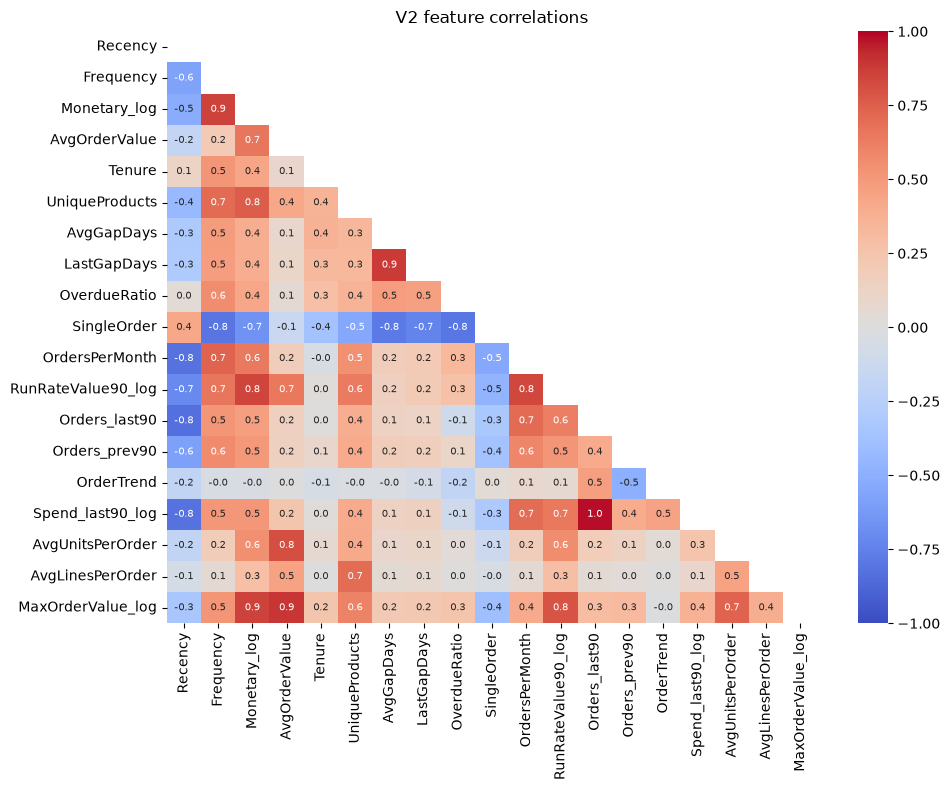

In [26]:
corr_new = feat[NUM_V2].corr(method='spearman')
mask = np.triu(np.ones_like(corr_new, dtype=bool))
plt.figure(figsize=(10, 8))
sns.heatmap(corr_new, mask=mask, cmap='coolwarm', vmin=-1, vmax=1, annot=True, fmt='.1f', annot_kws={'size': 7})
plt.title('V2 feature correlations')
plt.tight_layout()
plt.savefig('../../reports/feature_correlation_v2.png', dpi=150)
plt.show()

Jin pairs ka correlation 0.9+ hai (jaise Frequency aur Orders_last90), unme se ek model ko kuch alag nahi dega. Tree models ko isse zyada fark nahi padta, lekin LogReg ke coefficients ko ek-ek karke padhna mushkil ho jaata hai (Day 65 ki warning).

6. Asli sawaal: kya naye features sach mein madad karte hain? (sirf train par, CV se)

In [34]:
import joblib
from sklearn.base import clone
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from imblearn.pipeline import Pipeline as ImbPipeline

idx_tr, idx_te = train_test_split(feat.index, test_size=0.2, random_state=42, stratify=feat['Churned'])
X_test_saved = pd.read_csv('../../data/processed/X_test.csv')
print("Split same hai:", np.allclose(feat.loc[idx_te, 'Recency'].values, X_test_saved['Recency'].values))

y_tr = feat.loc[idx_tr, 'Churned']
X1_tr, X2_tr = make_xy(feat, NUM_V1).loc[idx_tr], make_xy(feat, NUM_V2).loc[idx_tr]

def logreg(num_cols):
    prep = ColumnTransformer([('s', StandardScaler(), num_cols)], remainder='passthrough')
    return ImbPipeline([('prep', prep), ('m', LogisticRegression(max_iter=5000, class_weight='balanced'))])

tree = clone(joblib.load('../model/decision_tree_tuned.joblib'))     # same hyperparameters

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = ['f1', 'roc_auc', 'average_precision', 'recall']

rows, folds = [], {}
for name, model, X in [('LogReg v1', logreg(NUM_V1), X1_tr), ('LogReg v2', logreg(NUM_V2), X2_tr),
                       ('Tree v1', tree, X1_tr), ('Tree v2', tree, X2_tr)]:
    r = cross_validate(clone(model), X, y_tr, cv=cv, scoring=scoring)
    rows.append({'model': name, **{m: r[f'test_{m}'].mean() for m in scoring}, 'auc_std': r['test_roc_auc'].std()})
    folds[name] = r['test_roc_auc']

print(pd.DataFrame(rows).set_index('model').round(3))
print("\nAUC fold-wise fark (v2 - v1):")
print("LogReg:", (folds['LogReg v2'] - folds['LogReg v1']).round(3))
print("Tree  :", (folds['Tree v2'] - folds['Tree v1']).round(3))

Split same hai: True
              f1  roc_auc  average_precision  recall  auc_std
model                                                        
LogReg v1  0.745    0.794              0.820   0.720    0.013
LogReg v2  0.753    0.796              0.820   0.746    0.012
Tree v1    0.748    0.781              0.790   0.746    0.014
Tree v2    0.760    0.779              0.793   0.792    0.017

AUC fold-wise fark (v2 - v1):
LogReg: [ 0.002  0.002 -0.002  0.005  0.004]
Tree  : [ 0.007 -0.004  0.003 -0.01  -0.004]


Kaise padho:

- v2 ka AUC/AP har fold mein v1 se behtar hai, to naye features sach mein kaam ke hain.
- Fark fold-to-fold ulat-palat ho raha hai (kabhi + kabhi −) ya auc_std se chhota hai, to wo noise hai. Tab simple v1 rakho aur README mein likho ki naye features ne asli faida nahi diya. Yeh bhi ek valid, imandaar finding hai.
- Tree ke hyperparameters v1 par tune hue the, to tree v1 ko thoda faida hai. Tree v2 ko thoda aur tuning mil sake, yeh Day 84 ke GridSearchCV mein hoga.
- Yahan test set ko haath nahi lagaya.

7. v2 splits save karo (purane files overwrite mat karna)

In [35]:
y_te = feat.loc[idx_te, 'Churned']
assert np.array_equal(y_tr.values, pd.read_csv('../../data/processed/y_train.csv').squeeze().values)

X2 = make_xy(feat, NUM_V2)
X2.loc[idx_tr].to_csv('../../data/processed/X_train_v2.csv', index=False)
X2.loc[idx_te].to_csv('../../data/processed/X_test_v2.csv', index=False)
feat.to_csv('../../data/processed/customer_ml_dataset_v2.csv', index=False)
print(X2.shape, list(X2.columns))

(5283, 21) ['Recency', 'Frequency', 'Monetary_log', 'AvgOrderValue', 'Tenure', 'UniqueProducts', 'AvgGapDays', 'LastGapDays', 'OverdueRatio', 'SingleOrder', 'OrdersPerMonth', 'RunRateValue90_log', 'Orders_last90', 'Orders_prev90', 'OrderTrend', 'Spend_last90_log', 'AvgUnitsPerOrder', 'AvgLinesPerOrder', 'MaxOrderValue_log', 'Region_Rest of World', 'Region_UK']


Purane X_train.csv aur Day 70 ke saved models ko jaisa hai rehne do. Isse Day 70 ka comparison hamesha reproduce ho sakta hai, aur Day 83-85 mein v1 se fair comparison ban sakta hai.

8. README ke liye note (apne numbers se bharo):

## Feature Engineering v2
Added behavioral features from the pre-cutoff window only: purchase rhythm (AvgGapDays, OverdueRatio),
recent trend (Orders_last90 vs prev90), and a run-rate CLV-style value.
Leakage guarded by an invariance unit test (changing future rows does not change any feature).
CV effect on ROC-AUC: LogReg [X] -> [X], Tree [X] -> [X]. [Faida clear tha / noise tha, apna verdict likho]

practice questions:

1. OverdueRatio ke deciles banao aur har decile ka churn rate plot karo (sirf train par). Kya ratio badhne par churn monotonic badhta hai? Yeh ek achha interview chart hai.

2. Ek naya feature jodo: WeekendShare (past orders ka kitna hissa weekend par hua) ya AvgUnitPrice. Pehle invariance test mein add karo, phir CV mein dekho ki kuch farak padta hai ya nahi. “Zyada features = behtar” aksar galat hota hai.

3. Apne shabdon mein likho: tumne RunRateValue90 ko “CLV” kyun nahi kaha, aur asli predictive CLV (jaise BG/NBD model) alag kyun hota?